## IMPORTS

In [1]:
from datetime import datetime

import mlflow
from omegaconf import OmegaConf

from src.data import (
    create_splits,
    fill_none,
    load_data,
    make_pipeline,
    make_test_split,
)

d:\conda_envs\def_env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
cfg = OmegaConf.load('config.yaml')

In [3]:
import warnings

warnings.filterwarnings('ignore')

In [4]:
# NN imports
from src.nn import (  # noqa: I001
    create_dataloaders,
    MLP,
    create_optimizer,
    create_scheduler,
    create_loss_fn,
    run_optuna_study,
    prepare_full_data,
    train_final_nn,
    test_evaluation,
    save_model
)


## DATA PREPARATION

In [5]:
df = load_data(cfg)
df = fill_none(df)
df, test = make_test_split(cfg, df)
pipeline = make_pipeline(cfg, df)
df = create_splits(cfg, df)

## FULL REGRESSION RUN

2026/11/19 19:30:49 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_torch_19112026_1930' does not exist. Creating a new experiment.
[I 2026-11-19 19:30:49,091] A new study created in memory with name: optuna_study_torch_19112026_1930
  0%|          | 0/5 [00:00<?, ?it/s]2026/11/19 19:30:49 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|

[I 2026-11-19 19:31:20,174] Trial 0 finished with value: 0.1605244507155118 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.010292247147901223, 'nn.training.lr': 0.008123245085588688, 'nn.training.weight_decay': 0.002136832907235877, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8997037220101252}. Best is trial 0 with value: 0.1605244507155118.


Best trial: 0. Best value: 0.160524:  40%|████      | 2/5 [00:51<01:14, 24.98s/it]

[I 2026-11-19 19:31:40,884] Trial 1 finished with value: 0.37290004397810456 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 3, 'nn.model.dropout': 0.29620728443102123, 'nn.training.lr': 1.3783237455007187e-05, 'nn.training.weight_decay': 0.000269264691008618, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.9535954961421276}. Best is trial 0 with value: 0.1605244507155118.


Best trial: 0. Best value: 0.160524:  60%|██████    | 3/5 [01:24<00:56, 28.35s/it]

[I 2026-11-19 19:32:13,247] Trial 2 finished with value: 0.24524124112704657 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.15585553804470548, 'nn.training.lr': 0.00036324869566766035, 'nn.training.weight_decay': 0.00015375920235481777, 'nn.data.batch_size': 64, 'nn.training.momentum': 0.9700171965812533}. Best is trial 0 with value: 0.1605244507155118.


Best trial: 0. Best value: 0.160524:  80%|████████  | 4/5 [02:30<00:43, 43.31s/it]

[I 2026-11-19 19:33:19,481] Trial 3 finished with value: 0.7968603856770805 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 2, 'nn.model.dropout': 0.14046725484369038, 'nn.training.lr': 0.00042470585622618684, 'nn.training.weight_decay': 3.6618192203924288e-06, 'nn.data.batch_size': 128, 'nn.training.momentum': 0.8377559794914928}. Best is trial 0 with value: 0.1605244507155118.


Best trial: 0. Best value: 0.160524: 100%|██████████| 5/5 [13:51<00:00, 166.23s/it]


[I 2026-11-19 19:44:40,239] Trial 4 finished with value: 5.910898124734003 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.1654490124263246, 'nn.training.lr': 1.551225912648474e-05, 'nn.training.weight_decay': 1.753594952976443e-05, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8897208357807704}. Best is trial 0 with value: 0.1605244507155118.


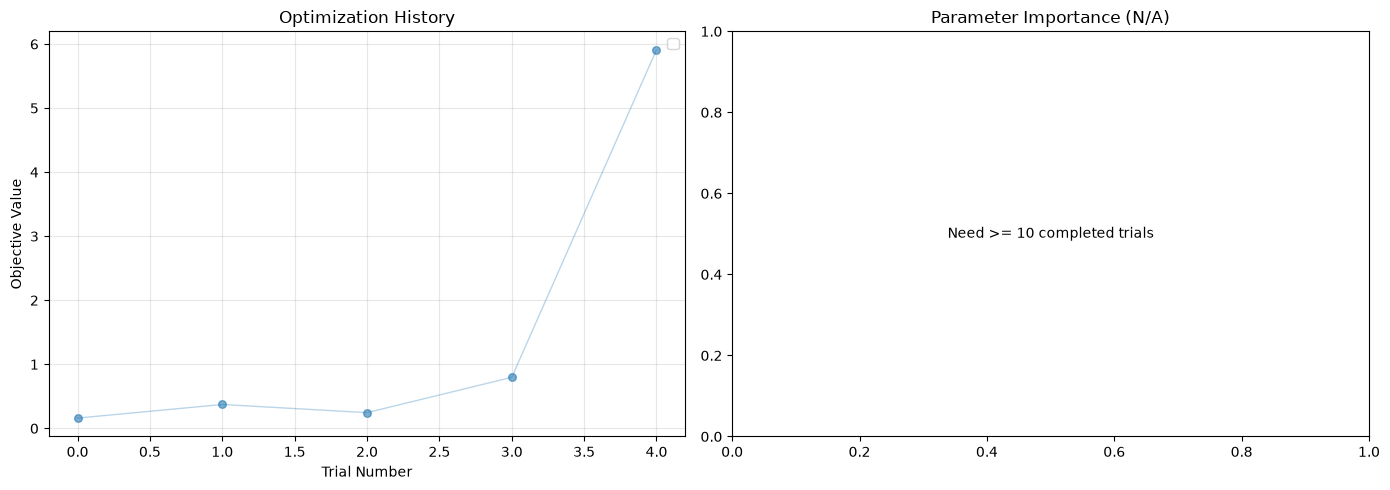

Best trial: 0
Best value: 0.1605
Best params: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.010292247147901223, 'nn.training.lr': 0.008123245085588688, 'nn.training.weight_decay': 0.002136832907235877, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8997037220101252}


In [6]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)

best_cfg, best_num_epochs = run_optuna_study(cfg, df, pipeline, experiment_name, show_plots=True)

In [9]:
best_num_epochs

[112, 65, 136, 86, 72]

In [7]:
df = load_data(cfg)
df = fill_none(df)
df, test = make_test_split(cfg, df)
pipeline = make_pipeline(cfg, df)
X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)

In [8]:
model = MLP(**best_cfg.nn.model)
optimizer = create_optimizer(model, best_cfg)
loss_fn = create_loss_fn(best_cfg)

In [10]:
train_loader, test_loader = create_dataloaders(best_cfg, X_train, y_train, X_test, y_test)

In [11]:
with mlflow.start_run(run_name="final_model"):
    model, train_losses = train_final_nn(model, train_loader, optimizer, loss_fn, best_cfg, )
    test_loss = test_evaluation(best_cfg, model, test_loader)
    save_model(model)

mlflow.end_run()

Test rmsle: 0.1726


## FULL CLASSIFICATION RUN

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [6]:
cfg = OmegaConf.load('binary_config.yaml')

In [7]:
# DATA PREPARATION
df, y = load_breast_cancer(return_X_y=True, as_frame=True)
df['target'] = y

scaler = StandardScaler()

pipeline = Pipeline(steps=[('scaler', scaler)])

df = create_splits(cfg, df) 


2026/11/17 20:52:31 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_torch_17112026_2052' does not exist. Creating a new experiment.
[I 2026-11-17 20:52:31,793] A new study created in memory with name: optuna_study_torch_17112026_2052
  0%|          | 0/5 [00:00<?, ?it/s]2026/11/17 20:52:31 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|

[I 2026-11-17 20:53:18,563] Trial 0 finished with value: 0.0633556917309761 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.010292247147901223, 'nn.training.lr': 0.008123245085588688, 'nn.training.weight_decay': 0.002136832907235877, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8997037220101252}. Best is trial 0 with value: 0.0633556917309761.


Best trial: 0. Best value: 0.0633557:  40%|████      | 2/5 [01:00<01:21, 27.26s/it]

[I 2026-11-17 20:53:32,149] Trial 1 finished with value: 0.07090787589550018 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 3, 'nn.model.dropout': 0.29620728443102123, 'nn.training.lr': 1.3783237455007187e-05, 'nn.training.weight_decay': 0.000269264691008618, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.9535954961421276}. Best is trial 0 with value: 0.0633556917309761.


Best trial: 0. Best value: 0.0633557:  60%|██████    | 3/5 [01:12<00:40, 20.44s/it]

[I 2026-11-17 20:53:44,484] Trial 2 finished with value: 0.16167697310447693 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.15585553804470548, 'nn.training.lr': 0.00036324869566766035, 'nn.training.weight_decay': 0.00015375920235481777, 'nn.data.batch_size': 64, 'nn.training.momentum': 0.9700171965812533}. Best is trial 0 with value: 0.0633556917309761.


Best trial: 0. Best value: 0.0633557:  80%|████████  | 4/5 [04:10<01:22, 82.72s/it]

[I 2026-11-17 20:56:42,681] Trial 3 finished with value: 0.09263520687818527 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 2, 'nn.model.dropout': 0.14046725484369038, 'nn.training.lr': 0.00042470585622618684, 'nn.training.weight_decay': 3.6618192203924288e-06, 'nn.data.batch_size': 128, 'nn.training.momentum': 0.8377559794914928}. Best is trial 0 with value: 0.0633556917309761.


Best trial: 0. Best value: 0.0633557: 100%|██████████| 5/5 [07:37<00:00, 91.54s/it] 


[I 2026-11-17 21:00:09,505] Trial 4 finished with value: 0.6109204292297363 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.1654490124263246, 'nn.training.lr': 1.551225912648474e-05, 'nn.training.weight_decay': 1.753594952976443e-05, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8897208357807704}. Best is trial 0 with value: 0.0633556917309761.


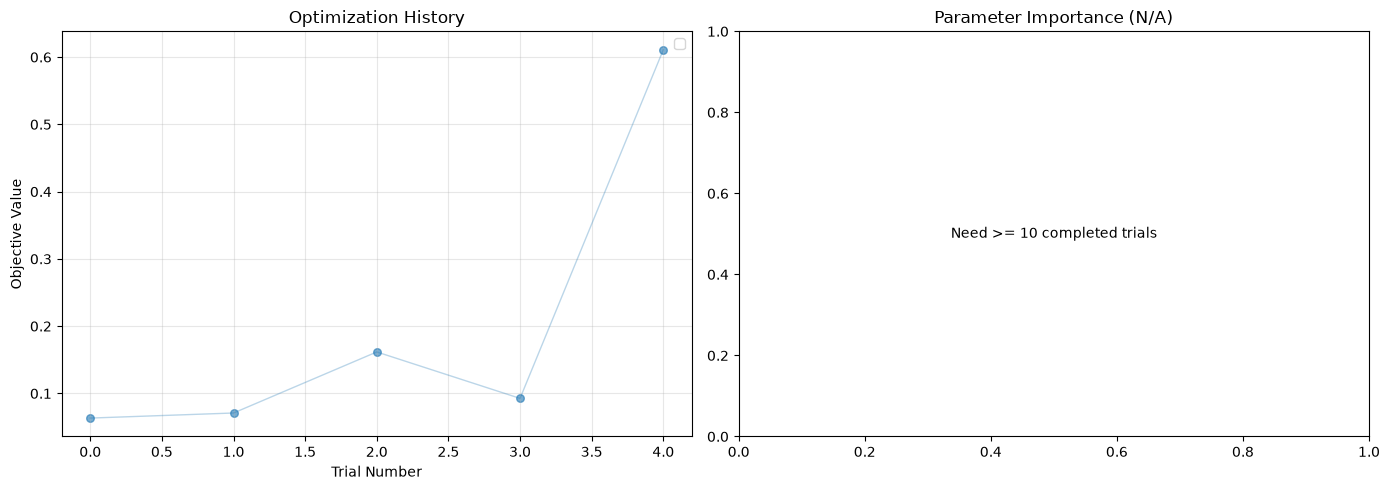

Best trial: 0
Best value: 0.0634
Best params: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.010292247147901223, 'nn.training.lr': 0.008123245085588688, 'nn.training.weight_decay': 0.002136832907235877, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8997037220101252}


In [8]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)

best_cfg, best_num_epochs = run_optuna_study(cfg, df, pipeline, experiment_name, show_plots=True)

In [9]:
df, y = load_breast_cancer(return_X_y=True, as_frame=True)
df['target'] = y
df, test = make_test_split(cfg, df)
X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)

In [10]:
model = MLP(**best_cfg.nn.model)
optimizer = create_optimizer(model, best_cfg)
loss_fn = create_loss_fn(best_cfg)
train_loader, test_loader = create_dataloaders(best_cfg, X_train, y_train, X_test, y_test)

In [11]:
with mlflow.start_run(run_name="final_model"):
    model, train_losses = train_final_nn(model, train_loader, optimizer, loss_fn, best_cfg, 25)
    test_loss = test_evaluation(best_cfg, model, test_loader)
    save_model(model)

mlflow.end_run()

Test log_loss: 0.6051


## MULTICLASS TEST RUN

In [1]:
from sklearn.datasets import load_iris

In [15]:
cfg = OmegaConf.load('multiclass_config.yaml')

df, y = load_iris(return_X_y=True, as_frame=True)
df['target'] = y

scaler = StandardScaler()
pipeline = Pipeline(steps=[('scaler', scaler)])

df = create_splits(cfg, df) 

2026/11/18 11:02:16 INFO mlflow.tracking.fluent: Experiment with name 'optuna_study_torch_18112026_1102' does not exist. Creating a new experiment.
[I 2026-11-18 11:02:16,717] A new study created in memory with name: optuna_study_torch_18112026_1102
Best trial: 0. Best value: 0.0815389:  20%|██        | 1/5 [01:02<04:11, 62.75s/it]

[I 2026-11-18 11:03:19,471] Trial 0 finished with value: 0.08153887093067169 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.010292247147901223, 'nn.training.lr': 0.008123245085588688, 'nn.training.weight_decay': 0.002136832907235877, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8997037220101252}. Best is trial 0 with value: 0.08153887093067169.


Best trial: 1. Best value: 0.0766819:  40%|████      | 2/5 [01:33<02:11, 43.92s/it]

[I 2026-11-18 11:03:50,211] Trial 1 finished with value: 0.07668187469244003 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 3, 'nn.model.dropout': 0.29620728443102123, 'nn.training.lr': 1.3783237455007187e-05, 'nn.training.weight_decay': 0.000269264691008618, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.9535954961421276}. Best is trial 1 with value: 0.07668187469244003.


Best trial: 1. Best value: 0.0766819:  60%|██████    | 3/5 [01:41<00:54, 27.39s/it]

[I 2026-11-18 11:03:57,927] Trial 2 finished with value: 0.20686352252960205 and parameters: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.15585553804470548, 'nn.training.lr': 0.00036324869566766035, 'nn.training.weight_decay': 0.00015375920235481777, 'nn.data.batch_size': 64, 'nn.training.momentum': 0.9700171965812533}. Best is trial 1 with value: 0.07668187469244003.


Best trial: 1. Best value: 0.0766819:  80%|████████  | 4/5 [04:15<01:17, 77.55s/it]

[I 2026-11-18 11:06:32,368] Trial 3 finished with value: 0.33109721541404724 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'relu', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 2, 'nn.model.dropout': 0.14046725484369038, 'nn.training.lr': 0.00042470585622618684, 'nn.training.weight_decay': 3.6618192203924288e-06, 'nn.data.batch_size': 128, 'nn.training.momentum': 0.8377559794914928}. Best is trial 1 with value: 0.07668187469244003.


Best trial: 1. Best value: 0.0766819: 100%|██████████| 5/5 [06:54<00:00, 82.82s/it] 


[I 2026-11-18 11:09:10,793] Trial 4 finished with value: 0.9789159893989563 and parameters: {'nn.training.optimizer': 'sgd', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 256, 'nn.model.num_layers': 4, 'nn.model.dropout': 0.1654490124263246, 'nn.training.lr': 1.551225912648474e-05, 'nn.training.weight_decay': 1.753594952976443e-05, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.8897208357807704}. Best is trial 1 with value: 0.07668187469244003.


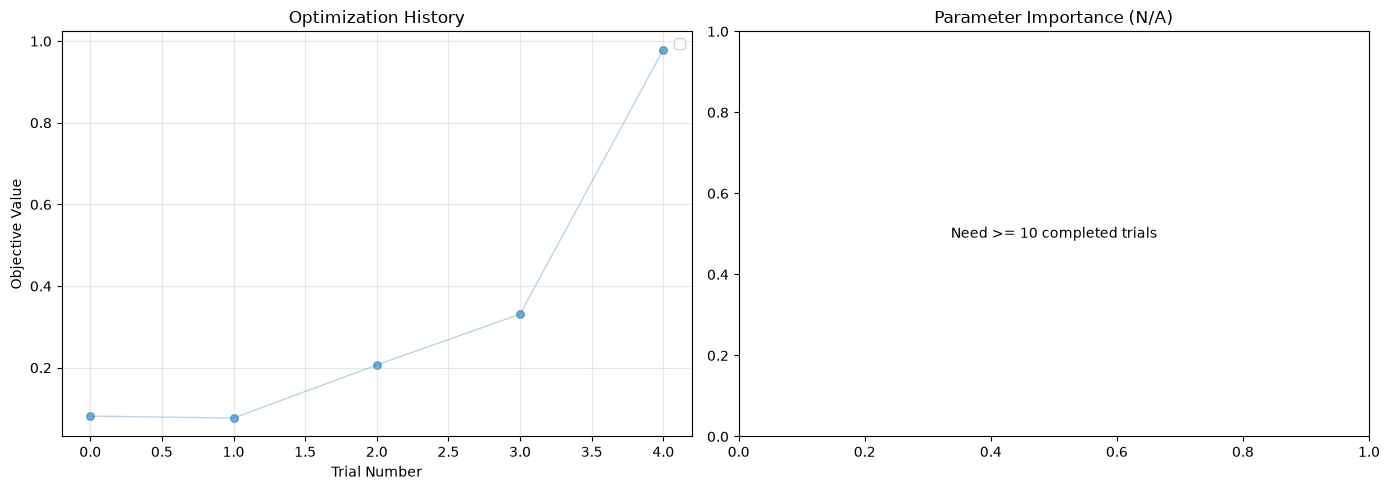

Best trial: 1
Best value: 0.0767
Best params: {'nn.training.optimizer': 'rmsprop', 'nn.model.activation': 'tanh', 'nn.model.hidden_dim': 128, 'nn.model.num_layers': 3, 'nn.model.dropout': 0.29620728443102123, 'nn.training.lr': 1.3783237455007187e-05, 'nn.training.weight_decay': 0.000269264691008618, 'nn.data.batch_size': 256, 'nn.training.momentum': 0.9535954961421276}


In [16]:
experiment_name = f"optuna_study_{cfg.model_class}_{datetime.now().strftime('%d%m%Y_%H%M')}"
mlflow.set_experiment(experiment_name)

best_cfg, best_num_epochs = run_optuna_study(cfg, df, pipeline, experiment_name, show_plots=True)

In [18]:
df, y = load_iris(return_X_y=True, as_frame=True)
df['target'] = y
df, test = make_test_split(cfg, df)
X_train, y_train, X_test, y_test = prepare_full_data(cfg, df, pipeline, test)

In [19]:
model = MLP(**best_cfg.nn.model)
optimizer = create_optimizer(model, best_cfg)
loss_fn = create_loss_fn(best_cfg)
train_loader, test_loader = create_dataloaders(best_cfg, X_train, y_train, X_test, y_test)

In [20]:
with mlflow.start_run(run_name="final_model"):
    model, train_losses = train_final_nn(model, train_loader, optimizer, loss_fn, best_cfg, 25)
    test_loss = test_evaluation(best_cfg, model, test_loader)
    save_model(model)

mlflow.end_run()

Test log_loss: 0.2904
